# Machine Learning Pipeline

This notebook builds a machine learning workflow for the Adult Income dataset, from data preparation to model evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import LabelEncoder


## 1. Load the Dataset

Load the dataset into a Pandas DataFrame so it can be inspected and prepared for training.

In [2]:
df = pd.read_csv(r"C:\Users\DELL\Downloads\archive (14).zip")

## 2. Explore the Dataset

Display the first rows to understand the columns and the structure of the data.

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### View the Last Rows

Display the last rows as another quick check of the dataset.

In [4]:
df.tail()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32560,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


## 3. Check for Duplicate Rows

Count duplicated rows before removing them.

In [5]:
df.duplicated().sum()

np.int64(24)

### Remove Duplicates

Remove duplicate records so the same row is not repeated in the dataset.

In [6]:
df = df.drop_duplicates()

In [7]:
df.duplicated().sum()

np.int64(0)

## 4. Inspect Question-Mark Values

Check object columns for values represented by `?`, which may indicate missing data.

In [8]:
for column in df.select_dtypes(include="object").columns:
    count = (df[column].astype(str).str.strip() == "?" ).sum()
    if count > 0:
        print(column , count)


workclass 1836
occupation 1843
native.country 582


### Convert Missing-Value Markers

Replace `?` values with `NaN` so missing values can be handled consistently.

In [9]:
df = df.replace(r'^\s*\?\s*$' , np.nan , regex=True)
print(df.isnull().sum()[df.isnull().sum() > 0]) 

workclass         1836
occupation        1843
native.country     582
dtype: int64


### Inspect the Cleaned Data

Display a sample of the data after converting the missing-value markers.

In [10]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


### Count Missing Values

Check which columns contain missing values.

In [11]:
df.isnull().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     582
income               0
dtype: int64

## 5. Feature Engineering

Create four additional features from existing columns. These features are retained initially and their usefulness can be evaluated during model selection.

- `age_group`: groups age into ranges; it may capture broad age patterns, while `age` preserves the exact value.
- `capital_net`: `capital.gain - capital.loss`; it combines the two capital columns and can be negative.
- `has_capital_gain`: indicates whether `capital.gain` is greater than zero (1) or not (0). This is binary, so it should not be log-transformed or IQR-capped.
- `hours_category`: groups weekly work hours; keep `hours.per.week` too initially because it contains more detail.


In [12]:
# 1. Create a copy
df = df.copy()

# 2. Create age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 35, 50, 100],
    labels=['young', 'adult', 'middle_age', 'older']
)

# 3. Net capital
df['capital_net'] = (
    df['capital.gain'] - df['capital.loss']
)

# 4. Has capital gain or not
df['has_capital_gain'] = (
    df['capital.gain'] > 0
).astype(int)

# 5. Categorize working hours
df['hours_category'] = pd.cut(
    df['hours.per.week'],
    bins=[0, 20, 40, 60, float('inf')],
    labels=['low', 'normal', 'high', 'very_high']
)

# Check the new features
print(df[['age_group', 'capital_net',
          'has_capital_gain', 'hours_category']].head())

print(df.shape)

    age_group  capital_net  has_capital_gain hours_category
0       older        -4356                 0         normal
1       older        -4356                 0            low
2       older        -4356                 0         normal
3       older        -3900                 0         normal
4  middle_age        -3900                 0         normal
(32537, 19)


## 6. Separate Features and Target

Use `income` as the target column (`y`) and the remaining columns as input features (`X`).

In [ ]:
X = df.drop("income", axis=1)
y = df["income"]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print(X.shape)
print(pd.Series(y).value_counts())


(32537, 18)
0    24698
1     7839
Name: count, dtype: int64


## 7. Import Pipeline Tools

Import the tools needed for preprocessing, feature selection, model training, tuning, and evaluation.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix
)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, TransformerMixin


## 8. Split Training and Test Data

Split the dataset into training and test sets. Stratification helps preserve the target-class proportions in both sets. Data-dependent preprocessing and resampling are fitted/applied within the training pipeline, not on the held-out test set.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class distribution before SMOTE:")
print(pd.Series(y_train).value_counts().sort_index())
print("\nTest class distribution (unchanged):")
print(pd.Series(y_test).value_counts().sort_index())


Training shape: (22775, 18)
Test shape: (9762, 18)

Training class distribution before SMOTE:
0    17288
1     5487
Name: count, dtype: int64

Test class distribution (unchanged):
0    7410
1    2352
Name: count, dtype: int64


## 9. Build the Preprocessing Steps

Identify numeric and categorical columns. Numeric values are imputed with the median and scaled; categorical values are imputed with the most frequent value and one-hot encoded. The IQR outlier capper is intentionally restricted to `fnlwgt` only. `capital.gain` and `capital.loss` are considered for `log1p` after checking their non-negative, right-skewed distributions. `capital_net` can be negative, so it uses a Yeo-Johnson transformation rather than `log1p`. `has_capital_gain` remains a binary feature without a skew transformation.


### Markdown Notes — Outlier Handling

- The IQR capper is intentionally applied to **`fnlwgt` only**, as requested.
- `fnlwgt` is an Adult Census sampling weight. IQR identifies statistical extremes, not necessarily errors, so inspect the values and document the decision to cap them.
- The capper's limits are learned during `fit()`; inside the model pipeline, this occurs on training folds only.
- The separate diagnostic cell below uses `X_train` rather than the full dataset.
- `capital.gain`, `capital.loss`, `capital_net`, and `has_capital_gain` are not IQR-capped by this capper.


In [16]:
X.skew(numeric_only=True)

age                  0.557663
fnlwgt               1.447703
education.num       -0.309500
capital.gain        11.949403
capital.loss         4.592702
hours.per.week       0.228759
capital_net         11.867499
has_capital_gain     3.014828
dtype: float64

In [17]:
class IQRcapper(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        
        self.numeric_features = ["fnlwgt"]
        X_numeric = X[self.numeric_features]

        Q1 = X_numeric.quantile(0.25)
        Q3 = X_numeric.quantile(0.75)
        IQR = Q3 - Q1

        self.lower = Q1 - 1.5 * IQR
        self.upper = Q3 + 1.5 * IQR

        return self

    def outlier(self, X):
        X = pd.DataFrame(X)
        for col in self.upper.index:
            outliers_lower = X[col] < self.lower[col]
            outliers_upper = X[col] > self.upper[col]

            if outliers_lower.any():
                print(f"outliers below lower bound in column: {col}")
                print(X.loc[outliers_lower, col])

            if outliers_upper.any():
                print(f"outliers above upper bound in column: {col}")
                print(X.loc[outliers_upper, col])

            if not outliers_lower.any() and not outliers_upper.any():
                print(f"no outliers in column: {col}")

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        numeric_columns = [col for col in self.numeric_features if col in X.columns]

        X.loc[:, numeric_columns] = X.loc[:, numeric_columns].clip(
            lower=self.lower[numeric_columns],
            upper=self.upper[numeric_columns],
            axis=1
        )

        return X


### Markdown Notes — Preprocessing

- Numeric, categorical, skewed, and signed-skew columns are assigned to separate preprocessing pipelines.
- Columns with `category` dtype are included in categorical encoding.
- `capital.gain` and `capital.loss` use `log1p` only if the data are non-negative and their distributions support the transformation.
- `capital_net` may contain negative values, so it uses the Yeo-Johnson transformation rather than `log1p`.
- `has_capital_gain` is binary and is not included in the skew-transformation columns.
- The columns assigned to different branches are kept separate to avoid processing the same feature twice.
- Preprocessing and SMOTE remain inside the model pipeline to avoid fitting transformations or resampling the held-out test set.


In [ ]:
skew_features = [col for col in ["capital.gain", "capital.loss"] if col in X.columns]
yeo_features = [col for col in ["capital_net"] if col in X.columns]
numeric_features = X.select_dtypes(include=np.number).columns.difference(skew_features + yeo_features)
categorical_features = X.select_dtypes(include=["object", "category"]).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


skew_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("skew", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])


yeo_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("power", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])


preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("skew", skew_pipeline, skew_features),
    ("yeo", yeo_pipeline, yeo_features)
])


In [ ]:

capper = IQRcapper()
capper.fit(X_train)
capper.outlier(X_train)


outliers above upper bound in column: fnlwgt
24483    462294
1637     553405
31901    746432
5772     429507
18250    419554
          ...  
8534     499249
9023     595000
4824     430828
16657    483450
10982    445940
Name: fnlwgt, Length: 702, dtype: int64


## 10. Train and Tune the Model

Combine outlier handling, preprocessing, feature selection, SMOTE, and Random Forest in one pipeline. GridSearchCV compares several hyperparameter settings using stratified cross-validation. F1 is used to select the best model because class balance matters; multiple metrics are also tracked for comparison.


In [ ]:

pipeline = Pipeline([
    ("outlier", IQRcapper()),
    ("preprocessing", preprocessor),
    ("feature_selection", SelectKBest(score_func=mutual_info_classif)),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1))
])


param_grid = {
    "feature_selection__k": [10, "all"],
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20]
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring=scoring,
    refit="f1",
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean CV F1:", grid_search.best_score_)


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\cluster\_supervised.py:68: UserWarning: Clustering metrics expects discrete values b

Best parameters: {'feature_selection__k': 'all', 'model__max_depth': 20, 'model__n_estimators': 300}
Best mean CV F1: 0.7060137661871423


## 11. Evaluate the Best Model

Evaluate the selected model once on the held-out test set. Report training and test metrics to help identify overfitting, alongside the classification report and confusion matrix. The test set is not used to select hyperparameters.


In [ ]:

best_model = grid_search.best_estimator_
y_train_pred = best_model.predict(X_train)
y_pred = best_model.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, zero_division=0)
test_recall = recall_score(y_test, y_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)
test_roc_auc = roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1])

print("Training accuracy:", train_accuracy)
print("Test accuracy:", test_accuracy)
print("Test precision:", test_precision)
print("Test recall:", test_recall)
print("Test F1:", test_f1)
print("Test ROC-AUC:", test_roc_auc)
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


Training accuracy: 0.9061690450054884
Test accuracy: 0.8360991600081951
Test precision: 0.6285909712722298
Test recall: 0.7814625850340136
Test F1: 0.6967399545109931
Test ROC-AUC: 0.9097852805089647

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.85      0.89      7410
           1       0.63      0.78      0.70      2352

    accuracy                           0.84      9762
   macro avg       0.78      0.82      0.79      9762
weighted avg       0.85      0.84      0.84      9762

Confusion matrix:
[[6324 1086]
 [ 514 1838]]


## 12. Track Performance and Save Results

Track the main training/test metrics, preserve the complete cross-validation results for comparing hyperparameters, and save the fitted pipeline so that preprocessing and model steps are stored together.


In [ ]:

results = pd.DataFrame({
    "Metric": [
        "Best CV F1", "Training Accuracy", "Test Accuracy",
        "Test Precision", "Test Recall", "Test F1", "Test ROC-AUC"
    ],
    "Score": [
        grid_search.best_score_, train_accuracy, test_accuracy,
        test_precision, test_recall, test_f1, test_roc_auc
    ]
})


cv_results = pd.DataFrame(grid_search.cv_results_).sort_values("rank_test_f1")
cv_results.to_csv("grid_search_cv_results.csv", index=False)


joblib.dump(best_model, "adult_income_random_forest_pipeline.joblib")

results


,Metric,Score
0,Best CV F1,0.706014
1,Training Accuracy,0.906169
2,Test Accuracy,0.836099
3,Test Precision,0.628591
4,Test Recall,0.781463
5,Test F1,0.696740
6,Test ROC-AUC,0.909785


## 13. Feature Importance and Permutation Importance

Random Forest feature importance shows which transformed features were most useful to the fitted trees. Permutation importance evaluates how much the held-out test F1 score changes when each original input column is shuffled. These are different views of importance; neither alone proves causation.


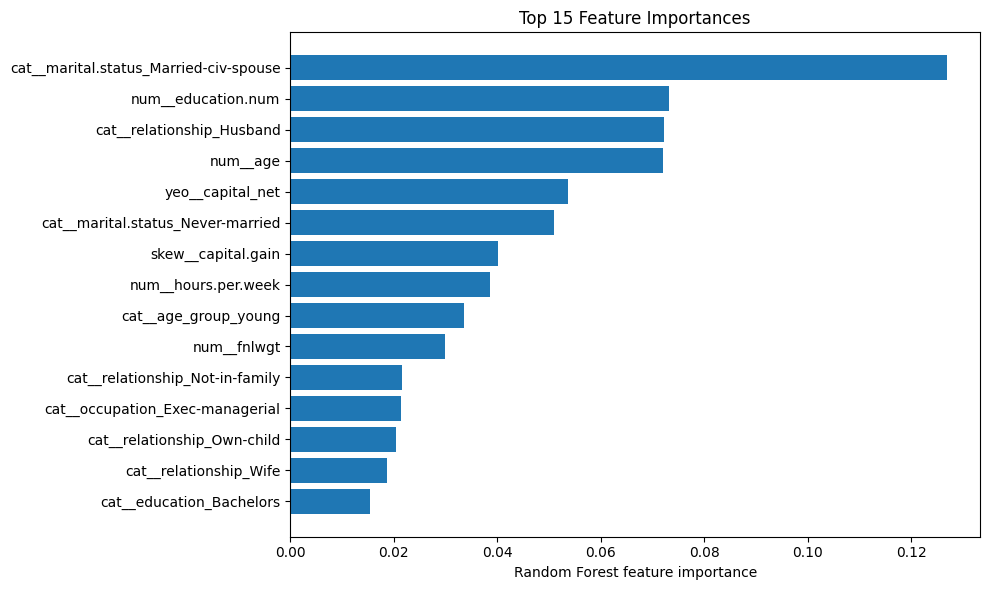

,Feature,Importance
31,cat__marital.status_Married-civ-spouse,0.126969
1,num__education.num,0.073267
50,cat__relationship_Husband,0.072259
0,num__age,0.072034
113,yeo__capital_net,0.053691
33,cat__marital.status_Never-married,0.050888
111,skew__capital.gain,0.040048
4,num__hours.per.week,0.038540
106,cat__age_group_young,0.033475
2,num__fnlwgt,0.029943


In [ ]:

feature_names = best_model.named_steps["preprocessing"].get_feature_names_out()
selected_mask = best_model.named_steps["feature_selection"].get_support()
selected_feature_names = np.asarray(feature_names)[selected_mask]
importances = best_model.named_steps["model"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": selected_feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top_features = feature_importance.head(15).sort_values("Importance")
plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Random Forest feature importance")
plt.title("Top 15 Feature Importances")
plt.tight_layout()
plt.show()

feature_importance.head(15)


### Interpreting the importance results

- The highest-ranked features are the transformed input features most used by this fitted Random Forest; one-hot encoded categories appear as separate features.
- `capital.gain`, `capital.loss`, `age`, `education.num`, and work-related features may be informative, but the actual ranking must be read from the output above rather than assumed in advance.
- Related or redundant features can share importance, so an individual feature's score may be lower when similar information is present in other columns.
- Feature importance describes model behavior, not a causal relationship.


In [ ]:

permutation_result = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=5, random_state=42, n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Permutation Importance Mean": permutation_result.importances_mean,
    "Permutation Importance Std": permutation_result.importances_std
}).sort_values("Permutation Importance Mean", ascending=False)

permutation_importance_df.head(15)


,Feature,Permutation Importance Mean,Permutation Importance Std
5,marital.status,0.078098,0.004885
7,relationship,0.048961,0.003982
6,occupation,0.026690,0.002666
4,education.num,0.026223,0.003594
15,capital_net,0.017553,0.001803
14,age_group,0.012292,0.003327
10,capital.gain,0.008578,0.001174
12,hours.per.week,0.007333,0.001824
0,age,0.006933,0.002512
3,education,0.006190,0.002650


### Comparing the two importance methods

Random Forest impurity importance is calculated from the fitted trees and applies to the transformed features used by the model. Permutation importance shuffles one original test-set column at a time and measures the drop in F1, so it reflects held-out predictive usefulness. If correlated columns share information, permutation importance can understate the value of any one of them. Compare the rankings rather than expecting them to be identical.


### Markdown Notes — Final Checks

- Re-run the notebook from the top after these changes so all outputs reflect the updated code.
- The dataset path in the loading cell is specific to the original computer; update it only if the file is stored elsewhere.
- `SelectKBest(k=10)` requires at least 10 features after preprocessing; if fewer are produced, remove `10` from the parameter grid or choose a smaller value.
- SMOTE remains inside the training pipeline, so resampling is applied to training folds and not to the held-out test set.
- Hyperparameter selection uses cross-validated F1; accuracy, precision, recall, F1, and ROC-AUC are also reported for evaluation.
- `grid_search_cv_results.csv` and `adult_income_random_forest_pipeline.joblib` are created when the notebook is run successfully.
- Feature-importance rankings and metric values should be interpreted from the actual outputs after running the notebook; they are not pre-filled or assumed.
